# MIE 2027 — results and figures
Run from the `Results/` folder. Each model's latest run folder is picked automatically; the printed folder names show which runs were used.

In [20]:
%matplotlib inline
import pandas as pd
from analysis import (latest_run, load_run, check_run, metrics_from_predictions,
                      plot_discrimination, plot_calibration, compare_to_zero_shot,
                      bootstrap_auroc, load_failed_ids, fallback_report)
import os
RESULTS_DIR = os.path.join("..", "Results")
FIG_DIR = "figures"
os.makedirs(FIG_DIR, exist_ok=True)

# display name -> run-folder prefix and score-cache folder (None for XGBoost: no cache)
MODELS = {
    "XGBoost":      ("xgboost",      None),
    "Qwen3.8-Flash": ("qwen3.8-flash-next", "qwen3.8-flash-next"), 
    "Jev":          ("jev",          "jev"),
    "Kev-9B":       ("kev-9b",       "kev-9b"),
    "Kev-0.8B":     ("kev-0.8b",     "kev-0.8b"),
}

## 1. Load runs and integrity checks
Check: repeats per n (full grid, 30 below 800 and 10 above), same test-set size, no NaN probabilities.

In [21]:
scores, predictions_by_model, prevalences = {}, {}, {}
for name, (prefix, _) in MODELS.items():
    folder = latest_run(prefix, RESULTS_DIR)
    print(f"{name}: {folder}")
    config, metrics, predictions = load_run(folder)
    check_run(name, config, metrics, predictions)
    scores[name] = metrics_from_predictions(predictions)
    predictions_by_model[name] = predictions
    prevalences[name] = predictions.drop_duplicates("nctId")["label"].mean()

assert len({round(p, 10) for p in prevalences.values()}) == 1, prevalences   # same test set
test_ids = {n: set(p["nctId"]) for n, p in predictions_by_model.items()}
assert all(ids == test_ids["XGBoost"] for ids in test_ids.values()), "test sets differ"
prevalence = prevalences["XGBoost"]
print(f"Test prevalence: {prevalence:.4f}")

XGBoost: ..\Results\xgboost_2026-10-14_132319
=== XGBoost ===
label=wilson_label  debug_n=None  commit=?
repeats per n: {25: 30, 50: 30, 100: 30, 200: 30, 400: 30, 800: 10, 1600: 10, 3200: 10, 6400: 10, 12800: 10}
test CTs per run: min=6341 max=6341  prevalence=0.0486
NaN probabilities: 0

Qwen3.8-Flash: ..\Results\qwen3.8-flash-next_2026-10-20_082136
=== Qwen3.8-Flash ===
label=wilson_label  debug_n=None  commit=?
repeats per n: {25: 30, 50: 30, 100: 30, 200: 30, 400: 30, 800: 10, 1600: 10, 3200: 10, 6400: 10, 12800: 10}
test CTs per run: min=6341 max=6341  prevalence=0.0486
NaN probabilities: 0

Jev: ..\Results\jev_2026-10-14_200442
=== Jev ===
label=wilson_label  debug_n=None  commit=?
repeats per n: {25: 30, 50: 30, 100: 30, 200: 30, 400: 30, 800: 10, 1600: 10, 3200: 10, 6400: 10, 12800: 10}
test CTs per run: min=6341 max=6341  prevalence=0.0486
NaN probabilities: 0

Kev-9B: ..\Results\kev-9b_2026-10-15_080227
=== Kev-9B ===
label=wilson_label  debug_n=None  commit=?
repeats per n:

## 2. Fallback CTs (for Methods)
CTs that could not be scored received the training prevalence. Report counts and check they barely affect AUROC.

In [22]:
rows = [fallback_report(name, predictions_by_model[name], load_failed_ids(os.path.join(RESULTS_DIR, cache)))
        for name, (_, cache) in MODELS.items() if cache is not None]
pd.DataFrame(rows).round(4)

,model,fallback_total,fallback_test,positive_rate_fallback_test,auroc_all,auroc_without_fallback
0,Qwen3.8-Flash,0,0,NaN,0.8171,0.8171
1,Jev,10,4,0.25,0.7672,0.7696
2,Kev-9B,0,0,NaN,0.6834,0.6834
3,Kev-0.8B,0,0,NaN,0.3914,0.3914


## 3. Zero-shot AUROC with 95% bootstrap CI (raw scores, test set)

In [23]:
ci = {name: bootstrap_auroc(predictions_by_model[name], n_boot=1000)
      for name, (_, cache) in MODELS.items() if cache is not None}
pd.DataFrame(ci, index=["AUROC", "CI low", "CI high"]).T.round(3)

,AUROC,CI low,CI high
Qwen3.8-Flash,0.817,0.794,0.841
Jev,0.767,0.745,0.791
Kev-9B,0.683,0.654,0.711
Kev-0.8B,0.391,0.365,0.421


## 4. Figures

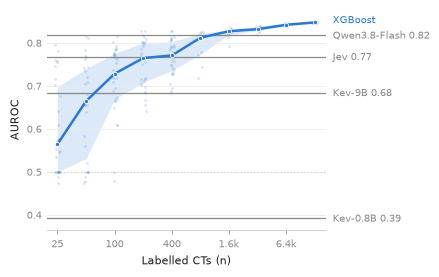

In [24]:
plot_discrimination(scores, path=os.path.join(FIG_DIR, "fig_discrimination"));

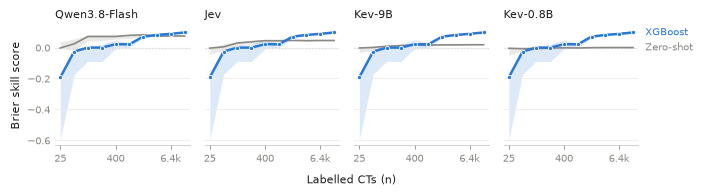

In [25]:
plot_calibration(scores, prevalence, path=os.path.join(FIG_DIR, "fig_calibration"));

## 5. XGBoost vs each zero-shot model, per budget
`share_supervised_better`: fraction of repeats where XGBoost is better (higher AUROC / lower Brier). `median_diff`: XGBoost minus zero-shot.

In [26]:
compare_to_zero_shot(scores).round(3)

share_supervised_better                               median_diff  \
zero_shot                     Jev Kev-0.8B Kev-9B Qwen3.8-Flash         Jev   
n                                                                             
25                          0.067      1.0  0.267         0.000      -0.203   
50                          0.167      1.0  0.400         0.000      -0.103   
100                         0.367      1.0  0.667         0.000      -0.039   
200                         0.500      1.0  0.867         0.100      -0.003   
400                         0.500      1.0  1.000         0.067       0.003   
800                         0.800      1.0  1.000         0.400       0.044   
1600                        1.000      1.0  1.000         0.800       0.059   
3200                        1.000      1.0  1.000         1.000       0.064   
6400                        1.000      1.0  1.000         1.000       0.075   
12800                       1.000      1.0  1.000         1.000       0.080   

                                         
zero_shot Kev-0.8B Kev-9B Qwen3.8-Flash  
n                                        
25           0.172 -0.120        -0.253  
50           0.273 -0.019        -0.153  
100          0.336  0.044        -0.089  
200          0.373  0.081        -0.053  
400          0.379  0.087        -0.047  
800          0.420  0.128        -0.006  
1600         0.435  0.143         0.010  
3200         0.440  0.148         0.014  
6400         0.450  0.158         0.025  
12800        0.456  0.164         0.030

In [27]:
compare_to_zero_shot(scores, metric="brier", calibrated=True).round(4)

share_supervised_better                                median_diff  \
zero_shot                     Jev Kev-0.8B  Kev-9B Qwen3.8-Flash         Jev   
n                                                                              
25                         0.0333   0.0000  0.0000        0.0000      0.0093   
50                         0.0333   0.0667  0.0000        0.0333      0.0024   
100                        0.1667   0.6333  0.2667        0.0667      0.0018   
200                        0.2333   0.6000  0.4333        0.1000      0.0014   
400                        0.3333   0.7333  0.5667        0.1000      0.0007   
800                        0.3000   0.7000  0.7000        0.2000      0.0009   
1600                       1.0000   1.0000  1.0000        0.2000     -0.0013   
3200                       0.9000   1.0000  1.0000        0.7000     -0.0016   
6400                       1.0000   1.0000  1.0000        0.9000     -0.0020   
12800                      1.0000   1.0000  1.0000        1.0000     -0.0024   

                                          
zero_shot Kev-0.8B  Kev-9B Qwen3.8-Flash  
n                                         
25          0.0088  0.0090        0.0106  
50          0.0011  0.0017        0.0039  
100        -0.0001  0.0007        0.0037  
200        -0.0003  0.0001        0.0030  
400        -0.0013 -0.0006        0.0022  
800        -0.0012 -0.0003        0.0026  
1600       -0.0033 -0.0026        0.0004  
3200       -0.0038 -0.0030       -0.0002  
6400       -0.0041 -0.0033       -0.0006  
12800      -0.0045 -0.0037       -0.0011